<a href="https://colab.research.google.com/github/HelenaFerds/Machine_Learning/blob/adicionar_documentacao/notbook/analise_dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CONECTANDO O GOOGLE COLAB NO MEU DRIVE

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**0.0 PIP INSTALL**

In [2]:
!pip install -U "numpy<2.3"
!pip install yfinance
!pip install -q ydata-profiling
!pip install xgboost
!pip install streamlit pyngrok
!pip install inflection
!pip install pyngrok

In [3]:
import numpy
print(numpy.__version__)

2.2.6


**1.0 IMPORTS**

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import plotly.express as px
import plotly.graph_objects as go
import inflection

from sklearn.preprocessing     import StandardScaler
from sklearn.linear_model      import LogisticRegression
from ydata_profiling           import ProfileReport
from sklearn.ensemble          import RandomForestClassifier
from xgboost                   import XGBClassifier
from pyngrok                   import ngrok

/tmp/ipykernel_5100/899459833.py:11: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling           import ProfileReport


1.2 CARREGANDO O MEU ARQUIVO DO DRIVE

In [5]:
df = pd.read_csv('/content/drive/MyDrive/Exercicios ML/PETR4.SA_historico.csv')
display(df.head())

,Price,Close,High,Low,Open,Volume
0,Ticker,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA
1,Date,NaN,NaN,NaN,NaN,NaN
2,2023-01-02,12.584511756896973,13.073177016293993,12.518623800215327,12.924930946453987,78424700
3,2023-01-03,12.266057014465332,12.683344663292472,12.150753338494864,12.595494742197669,96750300
4,2023-01-04,12.655887603759766,12.952381795475539,11.986031868508665,12.057409518040206,129504000


**1.0 COMEÇANDO A MANIPULAÇÕES**

Montei uma copia real para alterar o df2 e não o df

In [6]:
df2 = df.copy()

1.1 Renomenado as colunas para uma facíl manipulação

In [7]:
traducao = {
    'Price': 'preço',
    'Close': 'fechamento',
    'High': 'máximo',
    'Low': 'mínimo',
    'Open': 'abertura',
    'Volume': 'volume'
}

df2 = df2.rename(columns=traducao)

# Conferindo
print(df2.columns)

Index(['preço', 'fechamento', 'máximo', 'mínimo', 'abertura', 'volume'], dtype='object')


1.2 Dimensão dos dados

In [8]:
print( 'Numeros das linhas: {}'.format( df2.shape[0] ) )
print( 'Numeros das colunas: {}'.format( df2.shape[1] ) )

Numeros das linhas: 604
Numeros das colunas: 6


1.3 tipos de dados

In [9]:
df2.dtypes

,0
preço,object
fechamento,object
máximo,object
mínimo,object
abertura,object
volume,object


1.4 Valores ausentes

In [10]:
df2.isna().sum()

,0
preço,0
fechamento,1
máximo,1
mínimo,1
abertura,1
volume,1


1.5 Excluindo os valores ausentes

In [11]:
df2 = df2.dropna()

# Conferindo novamente
print(df2.isna().sum())

preço         0
fechamento    0
máximo        0
mínimo        0
abertura      0
volume        0
dtype: int64


1.6 Tornando os dados em numeros

In [12]:
df2.info() # aqui vendo como estão sendo caracterizados meus dados
df2.head() #aqui quero analisar como a tabela esta escrita

<class 'pandas.core.frame.DataFrame'>
Index: 603 entries, 0 to 603
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   preço       603 non-null    object
 1   fechamento  603 non-null    object
 2   máximo      603 non-null    object
 3   mínimo      603 non-null    object
 4   abertura    603 non-null    object
 5   volume      603 non-null    object
dtypes: object(6)
memory usage: 33.0+ KB


,preço,fechamento,máximo,mínimo,abertura,volume
0,Ticker,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA,PETR4.SA
2,2023-01-02,12.584511756896973,13.073177016293993,12.518623800215327,12.924930946453987,78424700
3,2023-01-03,12.266057014465332,12.683344663292472,12.150753338494864,12.595494742197669,96750300
4,2023-01-04,12.655887603759766,12.952381795475539,11.986031868508665,12.057409518040206,129504000
5,2023-01-05,13.111611366271973,13.199462325236455,12.710796013184165,12.815118176060976,73886000


In [13]:
#Aqui irei remover a linha Ticker da primeria linha pois esta dando erro ao ler o df2
df2 = df2.drop(index=0)
df2.head()#conferindo

,preço,fechamento,máximo,mínimo,abertura,volume
2,2023-01-02,12.584511756896973,13.073177016293993,12.518623800215327,12.924930946453987,78424700
3,2023-01-03,12.266057014465332,12.683344663292472,12.150753338494864,12.595494742197669,96750300
4,2023-01-04,12.655887603759766,12.952381795475539,11.986031868508665,12.057409518040206,129504000
5,2023-01-05,13.111611366271973,13.199462325236455,12.710796013184165,12.815118176060976,73886000
6,2023-01-06,13.034740447998047,13.353196578505878,12.930418305188464,13.144553340140066,51851500


Essa analise exploratorio de cima encontrou a raiz do problema do meu notebook anterior a este, pois a estrutura estava errada como se pode observar no terminal do codigo acima, temos o "Price" na tabel aoriginal que eu entend com "Preço" em df2, sendo que ele é o nome do nível superior de um cabeçalho hierárquico (MultiIndex) que o yfinance criou. Além disso, minhas linhas datas estava sendo interpretada como os valores da coluna Preço. Por fim, remover as: Price, Ticker e Date

1.7 Refazendo correções da tabela

In [14]:
df2 = df2[df2['preço'] != 'Ticker'].copy()#removendo a coluna ticker
df2.head()

,preço,fechamento,máximo,mínimo,abertura,volume
2,2023-01-02,12.584511756896973,13.073177016293993,12.518623800215327,12.924930946453987,78424700
3,2023-01-03,12.266057014465332,12.683344663292472,12.150753338494864,12.595494742197669,96750300
4,2023-01-04,12.655887603759766,12.952381795475539,11.986031868508665,12.057409518040206,129504000
5,2023-01-05,13.111611366271973,13.199462325236455,12.710796013184165,12.815118176060976,73886000
6,2023-01-06,13.034740447998047,13.353196578505878,12.930418305188464,13.144553340140066,51851500


In [15]:
df2.rename(columns={'preço': 'data'}, inplace=True)# renomeando a coluna preço para data
df2.head()

,data,fechamento,máximo,mínimo,abertura,volume
2,2023-01-02,12.584511756896973,13.073177016293993,12.518623800215327,12.924930946453987,78424700
3,2023-01-03,12.266057014465332,12.683344663292472,12.150753338494864,12.595494742197669,96750300
4,2023-01-04,12.655887603759766,12.952381795475539,11.986031868508665,12.057409518040206,129504000
5,2023-01-05,13.111611366271973,13.199462325236455,12.710796013184165,12.815118176060976,73886000
6,2023-01-06,13.034740447998047,13.353196578505878,12.930418305188464,13.144553340140066,51851500


In [16]:
df2['data'] = pd.to_datetime(df2['data'])# convertendo a data para datas de verdade, não apenas texto
df2.head()


,data,fechamento,máximo,mínimo,abertura,volume
2,2023-01-02,12.584511756896973,13.073177016293993,12.518623800215327,12.924930946453987,78424700
3,2023-01-03,12.266057014465332,12.683344663292472,12.150753338494864,12.595494742197669,96750300
4,2023-01-04,12.655887603759766,12.952381795475539,11.986031868508665,12.057409518040206,129504000
5,2023-01-05,13.111611366271973,13.199462325236455,12.710796013184165,12.815118176060976,73886000
6,2023-01-06,13.034740447998047,13.353196578505878,12.930418305188464,13.144553340140066,51851500


In [17]:
colunas_numericas = [
    'fechamento',
    'máximo',
    'mínimo',
    'abertura',
    'volume'
]

df2[colunas_numericas] = df2[colunas_numericas].apply(pd.to_numeric)#Converter os valores numéricos

df2.reset_index(drop=True, inplace=True) #Organizar o índice

In [18]:
#Verficando tudo
df2.info()

df2.dtypes

df2.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 602 entries, 0 to 601
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   data        602 non-null    datetime64[ns]
 1   fechamento  602 non-null    float64       
 2   máximo      602 non-null    float64       
 3   mínimo      602 non-null    float64       
 4   abertura    602 non-null    float64       
 5   volume      602 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 28.3 KB


,0
data,0
fechamento,0
máximo,0
mínimo,0
abertura,0
volume,0


In [19]:
df2.head()#Verificar as primeiras linhas

,data,fechamento,máximo,mínimo,abertura,volume
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500


In [20]:
print(f"Número de linhas: {df2.shape[0]}") #Verificar a dimensão dos dados
print(f"Número de colunas: {df2.shape[1]}")

Número de linhas: 602
Número de colunas: 6


In [21]:
df2.describe()#Análise estatística descritiva

,data,fechamento,máximo,mínimo,abertura,volume
count,602,602.000000,602.000000,602.000000,602.000000,6.020000e+02
mean,2024-03-16 01:04:35.083056384,25.227770,25.505254,24.950577,25.227120,4.536847e+07
min,2023-01-02 00:00:00,12.266057,12.683345,11.986032,12.057410,1.152660e+07
25%,2023-08-08 06:00:00,20.429045,20.564141,20.180275,20.429043,2.891125e+07
50%,2024-03-18 12:00:00,27.530890,27.877377,27.143522,27.500524,3.863190e+07
75%,2024-10-17 18:00:00,29.999607,30.258158,29.730444,30.041899,5.478190e+07
max,2025-06-02 00:00:00,33.540611,33.680008,33.375087,33.566748,2.303698e+08
std,NaN,6.155040,6.183765,6.143249,6.172147,2.453590e+07


In [22]:
df2.duplicated().sum()#Verificar se há registros duplicados

np.int64(0)

**1.8 Análise gráfica e extração de insights**

In [23]:
profile = ProfileReport(df2)

In [24]:
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 6/6 [00:00<00:00, 97.85it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [25]:
profile.to_file("relatorio.html")

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [26]:
from google.colab import files
files.download("relatorio.html")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**2.0 FEATURE ENGINEERING**

In [27]:
df3 = df2.copy()

2.1 Hipoteses

Hipótese 1 — Existe padrão temporal explorável
Você assume que o preço (ou retorno) não é totalmente aleatório, pelo menos em curto prazo.

Hipótese 2 — O passado ajuda a prever o futuro
Ou seja:
features devem ser baseadas SOMENTE em dados anteriores ao instante previsto (evitar leakage)

Hipótese 3 — O problema pode ser representado como:
Classificação (ex: sobe / desce / neutro)
OU
Regressão (retorno futuro)

In [28]:
#Criar a variável alvo (Target)
df3['retorno'] = df3['fechamento'].pct_change()

df3['classe'] = (df3['retorno'] > 0).astype(int)
df3.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700,NaN,0
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300,-0.025305,0
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000,0.031781,1
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000,0.036009,1
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500,-0.005863,0


Hipótese 1: "O passado recente influencia o próximo movimento"

Essa é uma hipótese clássica em séries temporais financeiras.

Então criamos lags (valores passados).

In [29]:
df3['fechamento_1d'] = df3['fechamento'].shift(1)
df3['fechamento_2d'] = df3['fechamento'].shift(2)
df3['fechamento_3d'] = df3['fechamento'].shift(3)

df3.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe,fechamento_1d,fechamento_2d,fechamento_3d
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700,NaN,0,NaN,NaN,NaN
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300,-0.025305,0,12.584512,NaN,NaN
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000,0.031781,1,12.266057,12.584512,NaN
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000,0.036009,1,12.655888,12.266057,12.584512
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500,-0.005863,0,13.111611,12.655888,12.266057


Hipótese 2: "A tendência influencia o movimento futuro"

In [30]:
#Média móvel de curto prazo
df3['media_5'] = df3['fechamento'].rolling(5).mean()

#Média móvel de longo prazo
df3['media_20'] = df3['fechamento'].rolling(20).mean()

df3.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe,fechamento_1d,fechamento_2d,fechamento_3d,media_5,media_20
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700,NaN,0,NaN,NaN,NaN,NaN,NaN
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300,-0.025305,0,12.584512,NaN,NaN,NaN,NaN
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000,0.031781,1,12.266057,12.584512,NaN,NaN,NaN
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000,0.036009,1,12.655888,12.266057,12.584512,NaN,NaN
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500,-0.005863,0,13.111611,12.655888,12.266057,12.730562,NaN


Hipótese 3: "Dias de alta volatilidade têm comportamento diferente"

In [31]:
df3['volatilidade_5'] = df3['retorno'].rolling(5).std()

df3.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe,fechamento_1d,fechamento_2d,fechamento_3d,media_5,media_20,volatilidade_5
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300,-0.025305,0,12.584512,NaN,NaN,NaN,NaN,NaN
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000,0.031781,1,12.266057,12.584512,NaN,NaN,NaN,NaN
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000,0.036009,1,12.655888,12.266057,12.584512,NaN,NaN,NaN
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500,-0.005863,0,13.111611,12.655888,12.266057,12.730562,NaN,NaN


Hipótese 4: "O volume negociado influencia o preço"

In [32]:
#Variação de volume
df3['variacao_volume'] = df3['volume'].pct_change()

#media de volume
df3['media_volume_5'] = df3['volume'].rolling(5).mean()

df3.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe,fechamento_1d,fechamento_2d,fechamento_3d,media_5,media_20,volatilidade_5,variacao_volume,media_volume_5
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300,-0.025305,0,12.584512,NaN,NaN,NaN,NaN,NaN,0.233671,NaN
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000,0.031781,1,12.266057,12.584512,NaN,NaN,NaN,NaN,0.338538,NaN
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000,0.036009,1,12.655888,12.266057,12.584512,NaN,NaN,NaN,-0.429469,NaN
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500,-0.005863,0,13.111611,12.655888,12.266057,12.730562,NaN,NaN,-0.298223,86083300.0


Hipótese 5: "A amplitude diária indica pressão de compra e venda"

In [33]:
df3['amplitude'] = (df3['máximo'] - df3['mínimo']) / df3['fechamento']

df3.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe,fechamento_1d,fechamento_2d,fechamento_3d,media_5,media_20,volatilidade_5,variacao_volume,media_volume_5,amplitude
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.044066
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300,-0.025305,0,12.584512,NaN,NaN,NaN,NaN,NaN,0.233671,NaN,0.043420
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000,0.031781,1,12.266057,12.584512,NaN,NaN,NaN,NaN,0.338538,NaN,0.076356
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000,0.036009,1,12.655888,12.266057,12.584512,NaN,NaN,NaN,-0.429469,NaN,0.037270
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500,-0.005863,0,13.111611,12.655888,12.266057,12.730562,NaN,NaN,-0.298223,86083300.0,0.032435


In [34]:
df3['candle'] = (df3['fechamento'] > df3['abertura']).astype(int)

df3.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe,fechamento_1d,fechamento_2d,fechamento_3d,media_5,media_20,volatilidade_5,variacao_volume,media_volume_5,amplitude,candle
0,2023-01-02,12.584512,13.073177,12.518624,12.924931,78424700,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.044066,0
1,2023-01-03,12.266057,12.683345,12.150753,12.595495,96750300,-0.025305,0,12.584512,NaN,NaN,NaN,NaN,NaN,0.233671,NaN,0.043420,0
2,2023-01-04,12.655888,12.952382,11.986032,12.057410,129504000,0.031781,1,12.266057,12.584512,NaN,NaN,NaN,NaN,0.338538,NaN,0.076356,1
3,2023-01-05,13.111611,13.199462,12.710796,12.815118,73886000,0.036009,1,12.655888,12.266057,12.584512,NaN,NaN,NaN,-0.429469,NaN,0.037270,1
4,2023-01-06,13.034740,13.353197,12.930418,13.144553,51851500,-0.005863,0,13.111611,12.655888,12.266057,12.730562,NaN,NaN,-0.298223,86083300.0,0.032435,0


**3.0 Filtrando**

In [35]:
df4 = df3.copy()

In [36]:
df4.dropna(inplace=True)

df4.head()

,data,fechamento,máximo,mínimo,abertura,volume,retorno,classe,fechamento_1d,fechamento_2d,fechamento_3d,media_5,media_20,volatilidade_5,variacao_volume,media_volume_5,amplitude,candle
19,2023-01-27,14.066978,14.401905,13.968146,14.374452,47681900,-0.024000,0,14.412888,14.791740,14.605062,14.517210,13.629377,0.019638,-0.349894,65266340.0,0.030835,0
20,2023-01-30,14.138357,14.314057,14.006582,14.193264,40683200,0.005074,1,14.066978,14.412888,14.791740,14.403005,13.707069,0.017100,-0.146779,55867360.0,0.021748,0
21,2023-01-31,14.314058,14.390927,14.012074,14.072471,54048900,0.012427,1,14.138357,14.066978,14.412888,14.344804,13.809469,0.019370,0.328531,53518340.0,0.026467,1
22,2023-02-01,14.116394,14.539172,13.973639,14.314057,56349200,-0.013809,0,14.314058,14.138357,14.066978,14.209735,13.882495,0.017184,0.042560,54421600.0,0.040062,0
23,2023-02-02,13.463010,14.171300,13.408103,14.006581,83823000,-0.046285,0,14.116394,14.314058,14.138357,14.019759,13.900064,0.023464,0.487563,56517240.0,0.056688,0


In [37]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 583 entries, 19 to 601
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   data             583 non-null    datetime64[ns]
 1   fechamento       583 non-null    float64       
 2   máximo           583 non-null    float64       
 3   mínimo           583 non-null    float64       
 4   abertura         583 non-null    float64       
 5   volume           583 non-null    int64         
 6   retorno          583 non-null    float64       
 7   classe           583 non-null    int64         
 8   fechamento_1d    583 non-null    float64       
 9   fechamento_2d    583 non-null    float64       
 10  fechamento_3d    583 non-null    float64       
 11  media_5          583 non-null    float64       
 12  media_20         583 non-null    float64       
 13  volatilidade_5   583 non-null    float64       
 14  variacao_volume  583 non-null    float64      

In [38]:
#so para uma leve correção
df4.reset_index(drop=True, inplace=True)

df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   data             583 non-null    datetime64[ns]
 1   fechamento       583 non-null    float64       
 2   máximo           583 non-null    float64       
 3   mínimo           583 non-null    float64       
 4   abertura         583 non-null    float64       
 5   volume           583 non-null    int64         
 6   retorno          583 non-null    float64       
 7   classe           583 non-null    int64         
 8   fechamento_1d    583 non-null    float64       
 9   fechamento_2d    583 non-null    float64       
 10  fechamento_3d    583 non-null    float64       
 11  media_5          583 non-null    float64       
 12  media_20         583 non-null    float64       
 13  volatilidade_5   583 non-null    float64       
 14  variacao_volume  583 non-null    float64  

**4.0 Separar os atributos (X) e o alvo (y)**

/tmp/ipykernel_5100/1933447048.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot( df4['fechamento'], kde=False  )


<Axes: xlabel='fechamento'>

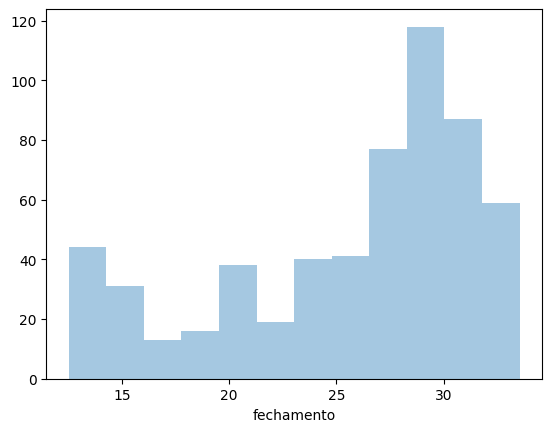

In [39]:
#4.0. PASSO 04 - ANALISE EXPLORATORIA DOS DADOS
sns.distplot( df4['fechamento'], kde=False  )

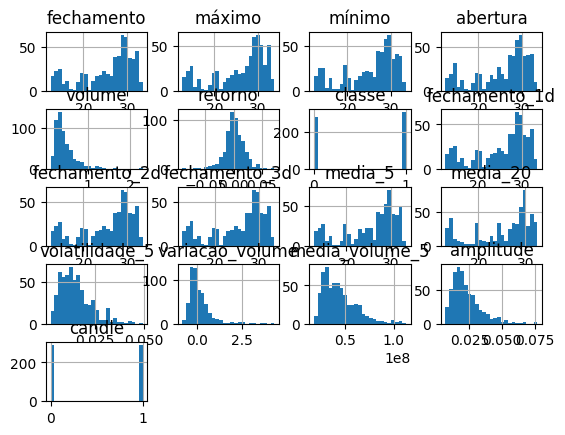

In [40]:
num_attributes = df4.select_dtypes(include=['int64', 'float64'])
num_attributes.hist(bins=25);
plt.show()


4.3. Analise Multivariada
4.3.1. Numerical Attributes

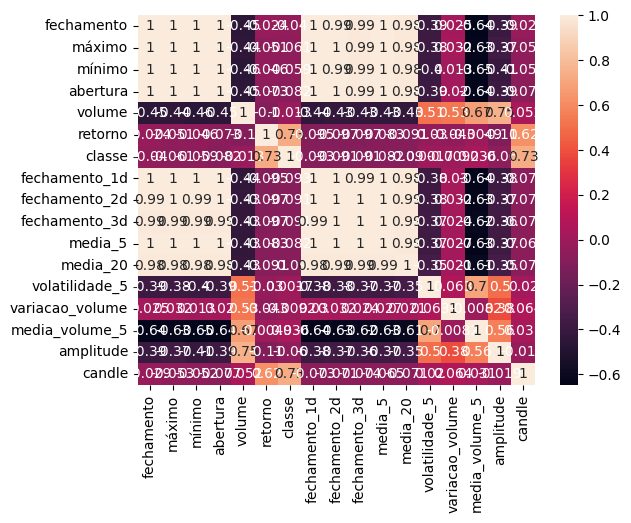

In [41]:
correlation = num_attributes.corr( method='pearson' )
sns.heatmap( correlation, annot=True );

In [42]:
# Reorganizando os índices do DataFrame
df4.reset_index(drop=True, inplace=True)

In [43]:
# Separação entre atributos e variável alvo
X = df4.drop(columns=['data', 'classe'])

# Variável que o modelo deve prever
y = df4['classe']

In [44]:
# Definindo o ponto de separação temporal
ponto_corte = int(len(df4) * 0.8)
print(ponto_corte)

466


Treinando o model

In [45]:
# Dados de treinamento (período mais antigo)
X_train = X.iloc[:ponto_corte]
y_train = y.iloc[:ponto_corte]

# Dados de teste (período mais recente)
X_test = X.iloc[ponto_corte:]
y_test = y.iloc[ponto_corte:]

In [46]:
print('Treinamento:', X_train.shape)
print('Teste:', X_test.shape)

Treinamento: (466, 16)
Teste: (117, 16)


In [47]:
print('Última data do treino:', df4['data'].iloc[ponto_corte - 1])
print('Primeira data do teste:', df4['data'].iloc[ponto_corte])

Última data do treino: 2024-12-06 00:00:00
Primeira data do teste: 2024-12-09 00:00:00


**Base de treinamneto**

In [48]:
# Criando o modelo Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
# Treinando o modelo com os dados históricos
model.fit(X_train, y_train)
# Realizando a previsão da direção do ativo
y_pred = model.predict(X_test)

In [49]:
# Comparando valores reais e previstos
resultado = pd.DataFrame({
    'real': y_test,
    'previsto': y_pred
})

resultado.head()

,real,previsto
466,1,1
467,1,1
468,1,1
469,0,0
470,0,0


In [50]:
datas_teste = df4['data'].iloc[ponto_corte:]
retornos_teste = df4['retorno'].iloc[ponto_corte:]

Matriz de erros e acertos

In [51]:
from sklearn.metrics import confusion_matrix

# Matriz de confusão
matriz = confusion_matrix(y_test, y_pred)

print(matriz)

[[60  2]
 [ 0 55]]


In [52]:
# Acertos e erros
acertos = (y_test == y_pred).sum()
erros = (y_test != y_pred).sum()

print(f'Quantidade de acertos: {acertos}')
print(f'Quantidade de erros: {erros}')

Quantidade de acertos: 115
Quantidade de erros: 2


AVALIAÇÃO DO MODELO

In [53]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
# Extraindo os valores da matriz
tn, fp, fn, tp = matriz.ravel()
especificidade = tn / (tn + fp)


print(f'Acurácia: {acuracia:.2%}')
print(f'Precisão: {precisao:.2%}')
print(f'F1-Score: {f1:.2%}')
print(f'Especificidade: {especificidade:.2%}')

Acurácia: 98.29%
Precisão: 96.49%
F1-Score: 98.21%
Especificidade: 96.77%


Criar um DataFrame com os resultados do período de teste

In [54]:
resultado_financeiro = pd.DataFrame({
    'data': datas_teste.values,
    'retorno_real': retornos_teste.values,
    'previsao_modelo': y_pred
})

resultado_financeiro.head()

,data,retorno_real,previsao_modelo
0,2024-12-09,0.025878,1
1,2024-12-10,0.003746,1
2,2024-12-11,0.009953,1
3,2024-12-12,-0.017886,0
4,2024-12-13,-0.006260,0


In [55]:
#Calcular o retorno da estratégia
resultado_financeiro['retorno_estrategia'] = resultado_financeiro.apply(
    lambda x: x['retorno_real'] if x['previsao_modelo'] == 1 else 0,
    axis=1
)

#Separar ganhos e perdas
ganhos = resultado_financeiro[
    resultado_financeiro['retorno_estrategia'] > 0
]

perdas = resultado_financeiro[
    resultado_financeiro['retorno_estrategia'] < 0
]

#Calcular o retorno financeiro dos ganhos
retorno_ganhos = ganhos['retorno_estrategia'].sum() * 100

print(f'Retorno total dos ganhos: {retorno_ganhos:.2f}%')

#Calcular o retorno financeiro das perdas
retorno_perdas = perdas['retorno_estrategia'].sum() * 100

print(f'Retorno total das perdas: {retorno_perdas:.2f}%')

#Calcular o retorno financeiro geral
retorno_total = (
    resultado_financeiro['retorno_estrategia'].sum()
) * 100

print(f'Retorno financeiro geral da estratégia: {retorno_total:.2f}%')

#Quantidade percentual de operações vencedoras e perdedoras
total_operacoes = len(resultado_financeiro[
    resultado_financeiro['previsao_modelo'] == 1
])

percentual_ganhos = (len(ganhos) / total_operacoes) * 100
percentual_perdas = (len(perdas) / total_operacoes) * 100

print(f'Operações com ganho: {percentual_ganhos:.2f}%')
print(f'Operações com perda: {percentual_perdas:.2f}%')

Retorno total dos ganhos: 58.22%
Retorno total das perdas: 0.00%
Retorno financeiro geral da estratégia: 58.22%
Operações com ganho: 96.49%
Operações com perda: 0.00%


In [56]:
#Criar uma tabela resumo para o Dashboard
resultado_retorno = pd.DataFrame({
    'Indicador': [
        'Retorno dos ganhos',
        'Retorno das perdas',
        'Retorno total',
        'Operações vencedoras',
        'Operações perdedoras'
    ],

    'Valor (%)': [
        retorno_ganhos,
        retorno_perdas,
        retorno_total,
        percentual_ganhos,
        percentual_perdas
    ]
})

resultado_retorno

,Indicador,Valor (%)
0,Retorno dos ganhos,58.216702
1,Retorno das perdas,0.000000
2,Retorno total,58.216702
3,Operações vencedoras,96.491228
4,Operações perdedoras,0.000000


Criação do DASHBOARDS

In [57]:
from pyngrok import ngrok

ngrok.set_auth_token("3FY7jmQAVXW1VsQFzx2oBf0xKnT_5oHcLekEHWwPCRTCgTTA7")

In [58]:
public_url = ngrok.connect(8501)

print(public_url)

NgrokTunnel: "https://strenuous-carry-retrain.ngrok-free.dev" -> "http://localhost:8501"


In [59]:
!ls

drive  relatorio.html  sample_data


In [60]:
import pandas as pd

resultado_acertos = pd.DataFrame({
    "Indicador": ["Acertos", "Erros"],
    "Quantidade": [acertos, erros]
})

resultado_acertos.to_csv("resultado_acertos.csv", index=False)

In [61]:
# Save DataFrames to CSV for Streamlit app
import pandas as pd

# Criando o DataFrame 'metricas' que estava faltando
metricas = pd.DataFrame({
    'Métrica': ['Acurácia', 'Precisão', 'F1-Score', 'Especificidade'],
    'Resultado': [acuracia, precisao, f1, especificidade]
})

df4.to_csv("df4.csv", index=False)
metricas.to_csv("metricas.csv", index=False)
resultado_retorno.to_csv("resultado_retorno.csv", index=False)

In [62]:
df4 = pd.read_csv("df4.csv")
metricas = pd.read_csv("metricas.csv")
resultado_retorno = pd.read_csv("resultado_retorno.csv")


In [63]:
%%writefile app.py


# =====================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# =====================================================

import streamlit as st
import pandas as pd
import plotly.express as px


# =====================================================
# LEITURA DOS DADOS GERADOS PELO NOTEBOOK
# =====================================================

df4 = pd.read_csv("df4.csv")
metricas = pd.read_csv("metricas.csv")
resultado_retorno = pd.read_csv("resultado_retorno.csv")
resultado_acertos = pd.read_csv("resultado_acertos.csv")


# Converter a coluna de data para datetime
df4["data"] = pd.to_datetime(df4["data"])

# =====================================================
# FILTRO DE PERÍODO POR ANO
# =====================================================

# Criando uma coluna com o ano
df4["ano"] = df4["data"].dt.year


# Criando o filtro na barra lateral
ano_selecionado = st.sidebar.selectbox(
    "Selecione o ano de treinamento",
    options=sorted(df4["ano"].unique())
)


# Filtrando os dados conforme o ano escolhido
df4_filtrado = df4[df4["ano"] == ano_selecionado]


# =====================================================
# CONFIGURAÇÃO DA PÁGINA
# =====================================================

st.set_page_config(
    page_title="Dashboard PETR4 - Random Forest",
    layout="wide"
)


# =====================================================
# TÍTULO DO DASHBOARD
# =====================================================

st.title("📈 Previsão da Direção da Ação PETR4 com Random Forest")


st.markdown("""
Este dashboard apresenta os resultados do modelo Random Forest aplicado à previsão da movimentação da ação PETR4.
""")
# =====================================================
# 1. SÉRIE TEMPORAL DA PETR4
# =====================================================

st.header("1. Série temporal do preço de fechamento da PETR4")


fig_preco = px.line(
    df4,
    x="data",
    y="fechamento",
    title="Evolução histórica do preço de fechamento"
)

st.plotly_chart(
    fig_preco,
    width="stretch"
)


# =====================================================
# 2. DISTRIBUIÇÃO DAS CLASSES
# =====================================================

st.header("2. Distribuição percentual das classes")


classes = (
    df4["classe"]
    .value_counts(normalize=True)
    .reset_index()
)

classes.columns = [
    "classe",
    "percentual"
]


classes["percentual"] = (
    classes["percentual"] * 100
)


classes["classe"] = classes["classe"].map({
    0: "Queda",
    1: "Alta"
})


fig_classes = px.bar(
    classes,
    x="classe",
    y="percentual",
    text="percentual",
    title="Percentual de altas e quedas"
)


fig_classes.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)


st.plotly_chart(
    fig_classes,
    width="stretch"
)


# =====================================================
# 3. QUANTIDADE DE ACERTOS E ERROS
# =====================================================

st.header("3. Resultado das previsões")


col1, col2 = st.columns(2)


acertos = resultado_acertos.loc[
    resultado_acertos["Indicador"] == "Acertos",
    "Quantidade"
].values[0]


erros = resultado_acertos.loc[
    resultado_acertos["Indicador"] == "Erros",
    "Quantidade"
].values[0]


col1.metric(
    "Quantidade de acertos",
    int(acertos)
)


col2.metric(
    "Quantidade de erros",
    int(erros)
)
# =====================================================
# 4. MÉTRICAS DE AVALIAÇÃO
# =====================================================

st.header("4. Avaliação do modelo")


metricas_exibicao = metricas.copy()


metricas_exibicao["Resultado"] = (
    metricas_exibicao["Resultado"] * 100
).round(2).astype(str) + "%"


st.table(metricas_exibicao)


# =====================================================
# 5. RETORNO FINANCEIRO
# =====================================================

st.header("5. Resultado financeiro da estratégia")


st.table(resultado_retorno)


# Encontrar o retorno total
retorno_total = resultado_retorno.loc[
    resultado_retorno["Indicador"] == "Retorno total",
    "Valor (%)"
].values[0]


# =====================================================
# 6. CONCLUSÃO DO MODELO
# =====================================================

st.header("6. Conclusão")


if retorno_total > 0:

    st.success(
        f"""
        O modelo Random Forest apresentou desempenho financeiro positivo,
        obtendo um retorno total de {retorno_total:.2f}% no período analisado.

        Os resultados indicam que os indicadores criados a partir da série
        temporal da PETR4 conseguiram capturar padrões relevantes de mercado.
        """
    )

else:

    st.error(
        f"""
        O modelo Random Forest apresentou retorno financeiro negativo de
        {retorno_total:.2f}% no período analisado.

        Isso indica que, apesar de identificar alguns padrões, o modelo
        ainda possui limitações para transformar suas previsões em uma
        estratégia de investimento lucrativa.
        """
    )


# =====================================================
# 7. REFERÊNCIAS
# =====================================================

st.header("7. Referências utilizadas")


st.markdown("""
- Breiman, L. (2001). Random Forests. Machine Learning.

- Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python.

- Yahoo Finance. Dados históricos da ação PETR4.SA.

- Fama, E. (1970). Efficient Capital Markets: A Review of Theory and Empirical Work.
""")

Writing app.py


In [64]:
!streamlit run app.py &>/content/log.txt &

In [65]:
!cat /content/log.txt

In [66]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)

print(public_url)

NgrokTunnel: "https://strenuous-carry-retrain.ngrok-free.dev" -> "http://localhost:8501"
